# Rotation and player analysis

Questions a coach asks after a match, answered straight from the warehouse marts: which rotations
win points, who is hitting efficiently, which setter-hitter connections work, and whether the
data behind all of it passed its checks.

Runs against either engine, no code changes:

| Engine | Environment |
| --- | --- |
| DuckDB (local target) | `VT_WAREHOUSE=duckdb` and `VT_DUCKDB_PATH=../.lake/warehouse.duckdb` (default) |
| BigQuery | `VT_WAREHOUSE=bigquery` and `GCP_PROJECT=<project>` (`pip install google-cloud-bigquery db-dtypes`) |

Every table used here is documented in [`docs/platform/data-dictionary.md`](../../docs/platform/data-dictionary.md).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

ENGINE = os.environ.get("VT_WAREHOUSE", "duckdb")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

if ENGINE == "bigquery":
    from google.cloud import bigquery
    _project = os.environ["GCP_PROJECT"]
    _client = bigquery.Client(project=_project)
    MARTS = f"`{_project}.vt_marts`"
    def q(sql: str) -> pd.DataFrame:
        return _client.query(sql.format(marts=MARTS)).to_dataframe()
else:
    import duckdb
    _conn = duckdb.connect(os.environ.get("VT_DUCKDB_PATH", "../.lake/warehouse.duckdb"), read_only=True)
    MARTS = "marts"
    def q(sql: str) -> pd.DataFrame:
        return _conn.sql(sql.format(marts=MARTS)).df()

print(f"engine: {ENGINE}")

engine: duckdb


## Season at a glance

One row per match: result, side-out %, break-point %, team hitting %. Same definitions as the app's Season page.

In [2]:
season = q("""
SELECT match_date, opponent, result, sets_won, sets_lost,
       sideout_rate, breakpoint_rate, hit_pct, kills, aces, blocks
FROM {marts}.agg_team_match_results
ORDER BY match_date
""")
season

,match_date,opponent,result,sets_won,sets_lost,sideout_rate,breakpoint_rate,hit_pct,kills,aces,blocks
0,2026-09-08,Block Party,W,2.0,1.0,0.614,0.485,0.255,43.0,5.0,7.0
1,2026-09-15,Net Gains,L,1.0,2.0,0.577,0.373,0.164,39.0,7.0,12.0
2,2026-09-22,Dig Deep,W,3.0,0.0,0.723,0.562,0.276,42.0,7.0,7.0
3,2026-09-29,Sideout Society,L,1.0,2.0,0.507,0.429,0.116,35.0,4.0,19.0
4,2026-10-06,Free Ballers,W,3.0,0.0,0.625,0.560,0.264,40.0,3.0,23.0
5,2026-10-13,Kill Shots,W,2.0,1.0,0.627,0.437,0.238,37.0,9.0,13.0
6,2026-10-20,Block Party,W,2.0,1.0,0.548,0.514,0.129,35.0,7.0,8.0


## Rotations

Side-out % (points won when receiving) is where matches are won; break-point % is how long we keep the serve. Rates are recomputed from numerators and denominators, never averaged.

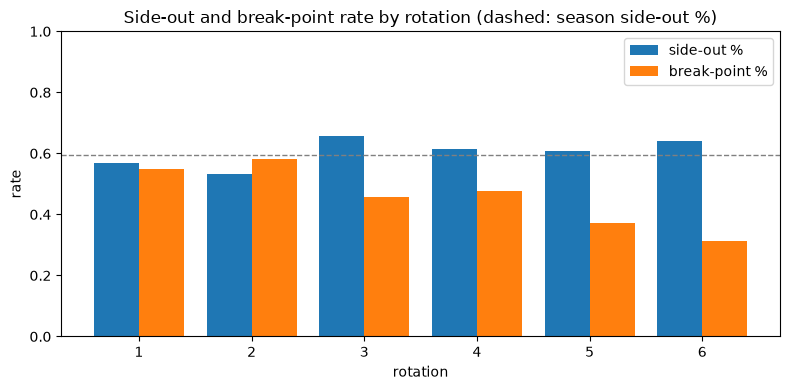

,rotation,rallies,sideout_opps,sideouts,sideout_rate,breakpoint_opps,breakpoints,breakpoint_rate,hit_pct
0,1,190.0,95.0,54.0,0.568,95.0,52.0,0.547,0.227
1,2,207.0,90.0,48.0,0.533,117.0,68.0,0.581,0.197
2,3,150.0,67.0,44.0,0.657,83.0,38.0,0.458,0.224
3,4,147.0,65.0,40.0,0.615,82.0,39.0,0.476,0.182
4,5,120.0,61.0,37.0,0.607,59.0,22.0,0.373,0.253
5,6,104.0,53.0,34.0,0.642,51.0,16.0,0.314,0.121


In [3]:
rot = q("""
SELECT rotation, rallies, sideout_opps, sideouts, sideout_rate,
       breakpoint_opps, breakpoints, breakpoint_rate, hit_pct
FROM {marts}.agg_rotation_season
ORDER BY rotation
""")
fig, ax = plt.subplots(figsize=(8, 4))
x = rot["rotation"]
ax.bar(x - 0.2, rot["sideout_rate"], width=0.4, label="side-out %")
ax.bar(x + 0.2, rot["breakpoint_rate"], width=0.4, label="break-point %")
ax.set_xlabel("rotation"); ax.set_ylabel("rate"); ax.set_ylim(0, 1); ax.set_xticks(x)
ax.axhline(rot["sideouts"].sum() / rot["sideout_opps"].sum(), ls="--", lw=1, color="gray")
ax.legend(); ax.set_title("Side-out and break-point rate by rotation (dashed: season side-out %)")
plt.tight_layout(); plt.show()
rot

### Match by match

A rotation that is weak every night is a lineup problem; one bad night is noise.

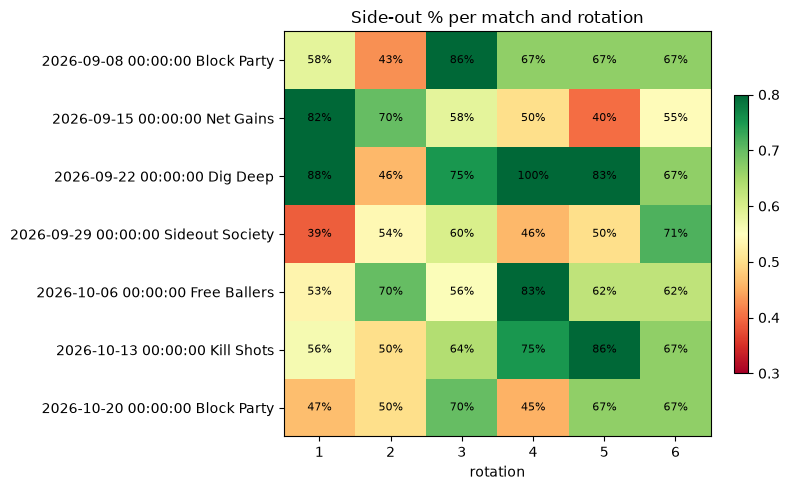

In [4]:
heat = q("""
SELECT match_date, opponent, rotation, sideout_rate
FROM {marts}.agg_rotation_performance
ORDER BY match_date, rotation
""")
pivot = heat.pivot_table(index=["match_date", "opponent"], columns="rotation", values="sideout_rate")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(pivot) + 1.5))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=0.3, vmax=0.8, aspect="auto")
ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels([f"{d} {o}" for d, o in pivot.index])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
ax.set_xlabel("rotation"); ax.set_title("Side-out % per match and rotation")
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

## Players

Hitting % against volume: a high percentage on a handful of swings is not the same as one on a hundred. Pass average is on the 0-3 scale.

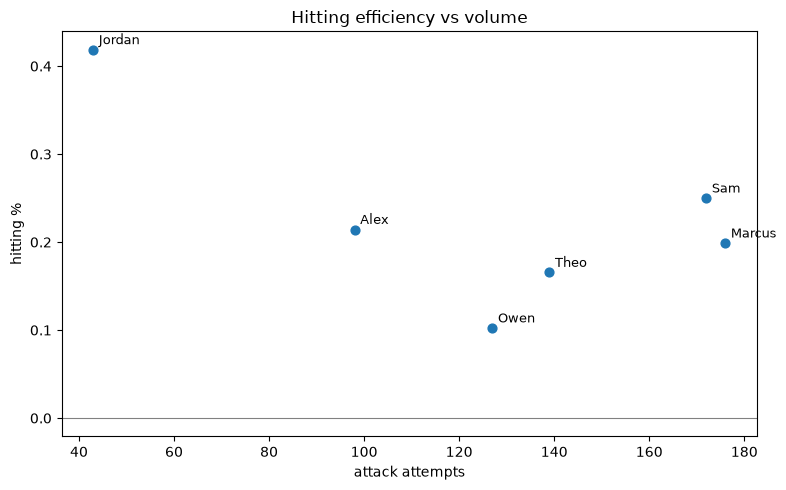

,player_name,position,matches_played,sets_played,kills,attack_attempts,hit_pct,aces,service_errors,passes,pass_avg,blocks,digs,assists
0,Sam,outside,7,21.0,71.0,172.0,0.250,4.0,6.0,71.0,1.746,16.0,48.0,0.0
1,Marcus,outside,7,21.0,64.0,176.0,0.199,11.0,10.0,132.0,1.962,22.0,71.0,0.0
2,Theo,middle,7,21.0,41.0,139.0,0.165,5.0,12.0,0.0,NaN,26.0,11.0,0.0
3,Alex,opposite,5,15.0,37.0,98.0,0.214,9.0,5.0,42.0,1.833,4.0,61.0,0.0
4,Owen,middle,7,21.0,36.0,127.0,0.102,3.0,11.0,0.0,NaN,19.0,7.0,0.0
5,Jordan,outside,2,6.0,22.0,43.0,0.419,1.0,4.0,19.0,1.632,2.0,28.0,0.0
6,Maya,setter,7,21.0,0.0,0.0,NaN,9.0,11.0,0.0,NaN,0.0,0.0,271.0
7,Priya,libero,7,21.0,0.0,0.0,NaN,0.0,0.0,120.0,2.092,0.0,112.0,0.0


In [5]:
players = q("""
SELECT player_name, position, matches_played, sets_played, kills, attack_attempts, hit_pct,
       aces, service_errors, passes, pass_avg, blocks, digs, assists
FROM {marts}.agg_player_season
ORDER BY kills DESC
""")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(players["attack_attempts"], players["hit_pct"], s=40)
for _, r in players.iterrows():
    if r["attack_attempts"] > 0:
        ax.annotate(r["player_name"], (r["attack_attempts"], r["hit_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="gray", lw=0.8); ax.set_xlabel("attack attempts"); ax.set_ylabel("hitting %")
ax.set_title("Hitting efficiency vs volume"); plt.tight_layout(); plt.show()
players

## Setter-hitter connections

Within a rally the k-th attack is paired with the k-th setting touch; see the data dictionary for the caveat on overpass kills.

In [6]:
q("""
SELECT setter_name, hitter_name, hitter_position, attempts, kills, errors, hit_pct, kill_rate
FROM {marts}.agg_setter_hitter_pairs
ORDER BY attempts DESC
""")

,setter_name,hitter_name,hitter_position,attempts,kills,errors,hit_pct,kill_rate
0,Maya,Marcus,outside,176,64.0,29.0,0.199,0.364
1,Maya,Sam,outside,172,71.0,28.0,0.250,0.413
2,Maya,Theo,middle,139,41.0,18.0,0.165,0.295
3,Maya,Owen,middle,127,36.0,23.0,0.102,0.283
4,Maya,Alex,opposite,98,37.0,16.0,0.214,0.378
5,Maya,Jordan,outside,43,22.0,4.0,0.419,0.512


## Can we trust it?

The latest pipeline run's quality checks and reconciliation. A red row here is the reason a number above should not be presented to the coaching staff yet.

In [7]:
checks = q("""
SELECT check_name, severity, violations, passed
FROM {marts}.dq_check_results
WHERE run_id = (SELECT MAX(run_id) FROM {marts}.dq_check_results)
ORDER BY passed, severity, check_name
""")
display(checks)
display(q("""
SELECT table_name, source_rows, warehouse_rows, difference, status
FROM {marts}.reconciliation_source_counts
WHERE run_id = (SELECT MAX(run_id) FROM {marts}.reconciliation_source_counts)
ORDER BY table_name
"""))
display(q("""
SELECT status, COUNT(*) AS sets FROM {marts}.rec_scoresheet_sets GROUP BY status ORDER BY status
"""))
q("""
SELECT match_date, opponent, player_name, sheet_kills, app_kills, kills_diff, status
FROM {marts}.rec_scoresheet_players
WHERE status = 'mismatch'
ORDER BY match_date
""")

,check_name,severity,violations,passed
0,events_and_rallies_reference_known_match,error,0,True
1,events_reference_known_player,error,0,True
2,hit_pct_within_bounds,error,0,True
3,one_team_row_per_rally,error,0,True
4,rotation_in_range,error,0,True
5,running_score_is_continuous,error,0,True
6,serve_events_only_when_serving,error,0,True
7,set_scores_match_rally_outcomes,error,0,True
8,staging_keys_are_unique,error,0,True
9,freshness,warn,0,True


,table_name,source_rows,warehouse_rows,difference,status
0,lineups,3,3,0,match
1,matches,7,7,0,match
2,night_plans,1,1,0,match
3,players,9,9,0,match
4,rallies,918,918,0,match
5,stat_event_summaries,0,0,0,match
6,stat_events,4000,4000,0,match


,status,sets
0,match,17
1,mismatch,1
2,missing_in_app,1
3,missing_in_scoresheet,3


,match_date,opponent,player_name,sheet_kills,app_kills,kills_diff,status
0,2026-09-15,Net Gains,Marcus,7,9.0,-2.0,mismatch


## Next questions

- Does side-out % by rotation change with the lineup (`agg_rotation_performance.lineup_name`)?
- Which rotation produces the most attack errors per attempt?
- Blend `fct_rallies.point_type` with rally length (`n_touches`) to see whether long rallies favour us.